# Entrenamiento y selección de modelos - House Pricing

Torneo de modelos de regresión, ensambles y redes neuronales para predecir `SalePrice`. Cada modelo se optimiza con `GridSearchCV` y validación cruzada de 10 folds, y se compara contra el conjunto de validación con el RMSE real (en dólares) y el RMSE normalizado al rango. Todo el proceso se registra en MLflow y los tres mejores modelos se publican en el Model Registry: el primero como `champion` y los dos siguientes como challengers.

## 1. Librerías

Importación de las librerías para manipulación de datos, visualización, validación cruzada, optimización de hiperparámetros y modelos de sklearn, y seguimiento de experimentos con MLflow.

In [1]:
import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.data
import numpy as np
import pandas as pd
import yaml
from mlflow import MlflowClient
from mlflow.models import infer_signature
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import make_scorer, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from house_pricing.config import (
    CHALLENGER_ALIASES,
    CHAMPION_ALIAS,
    MLFLOW_EXPERIMENT_TRAINING,
    MODELS_DIR,
    PROJ_ROOT,
    RAW_DATA_DIR,
    REGISTERED_MODEL_NAME,
    SKOPS_TRUSTED_TYPES,
)
from house_pricing.tracking import configurar_mlflow

C:\Users\MO\anaconda3\envs\env_house_pricing\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-11-10 19:21:31.803 | INFO     | house_pricing.config:<module>:11 - PROJ_ROOT path is: C:\Users\MO\Desktop\Business Intelligence\8vo. trimestre\Product_Development\Clase\House_pricing


## 2. Carga de configuración y datos

Lectura de la configuración y de los datos crudos, y reproducción exacta de la partición 80/20 del notebook de preprocesamiento (`TEST_SIZE` y `RANDOM_STATE` deben coincidir con `2.0-mo-preprocesamiento-modelo`). Se parte de los datos crudos y no de los CSV procesados, para que el preprocesamiento se reajuste dentro de cada fold de la validación cruzada (sección 3).

In [2]:
CONFIG_PATH = PROJ_ROOT / "pipeline_config.yaml"
DATA_PATH = RAW_DATA_DIR
TRAIN_FILE = "train.csv"

# Deben coincidir con el notebook 2.0-mo-preprocesamiento-modelo
TEST_SIZE = 0.2
RANDOM_STATE = 42
REFERENCE_YEAR = "YrSold"

with open(CONFIG_PATH, encoding="utf-8") as f:
    pipeline_config = yaml.safe_load(f)

TARGET = pipeline_config["TARGET"]
INPUT_FEATURES = pipeline_config["MODEL_FEATURES"] + [REFERENCE_YEAR]

train_raw = pd.read_csv(DATA_PATH / TRAIN_FILE)

X = train_raw[INPUT_FEATURES]
y = np.log1p(train_raw[TARGET])

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

print(f"X_train: {X_train.shape} | X_val: {X_val.shape}")

X_train: (1168, 31) | X_val: (292, 31)


## 3. Pipeline de preprocesamiento sin fuga de datos

Carga del pipeline de ingeniería de características definido en el notebook de preprocesamiento. Se usa una copia **sin ajustar** (`clone`), que se combina con cada modelo en un único `Pipeline`. Así, en cada fold de la validación cruzada la imputación, el encoder por target, el capping, Yeo-Johnson y el escalado se ajustan solo con los folds de entrenamiento, y el fold de prueba nunca participa en su ajuste. El conjunto de validación queda fuera de todo el proceso de búsqueda.

In [3]:
PIPELINE_PATH = MODELS_DIR / "preprocessing_pipeline.pkl"

preprocessing = clone(joblib.load(PIPELINE_PATH))
preprocessing

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('categorical_imputer', ...), ('numerical_imputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,imputation_method,'frequent'
,variables,"['Neighborhood', 'ExterQual', ...]"
,ignore_format,True
,fill_value,'Missing'
,return_object,False
,variables,"['GrLivArea', 'GarageArea', ...]"
,imputation_method,'median'


## 4. Esquema de validación y métricas

- **Validación cruzada**: `KFold` con 10 folds y mezcla aleatoria.
- **Métrica de optimización**: RMSE real. Como el modelo predice `log1p(SalePrice)`, el scorer revierte el target y la predicción con `expm1` antes de calcular el error en dólares.
- **RMSE normalizado al rango (NRMSE)**: RMSE real dividido entre el rango (`max − min`) de `SalePrice` real en entrenamiento. Expresa el error como proporción del rango de precios y permite compararlo entre conjuntos.

In [4]:
N_FOLDS = 10

cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)


def rmse_real(y_true_log, y_pred_log):
    """RMSE en dólares a partir del target y la predicción en escala log1p."""
    return root_mean_squared_error(np.expm1(y_true_log), np.expm1(y_pred_log))


rmse_real_scorer = make_scorer(rmse_real, greater_is_better=False)

TARGET_RANGE = np.expm1(y_train).max() - np.expm1(y_train).min()
print(f"Rango de {TARGET} en entrenamiento: {TARGET_RANGE:,.0f}")

Rango de SalePrice en entrenamiento: 710,100


## 5. Modelos e hiperparámetros

Definición de los participantes del torneo y de su rejilla de hiperparámetros (al menos 3 configuraciones por modelo). Las rejillas priorizan los parámetros que controlan el sobreajuste:

- **Regresiones regularizadas** (`Ridge`, `Lasso`, `ElasticNet`): fuerza de la penalización (`alpha`) y mezcla L1/L2 (`l1_ratio`).
- **Ensambles** (`RandomForest`, `GradientBoosting`): profundidad, tamaño mínimo de las hojas, fracción de variables y tasa de aprendizaje.
- **Red neuronal** (`MLPRegressor`): arquitectura, regularización L2 (`alpha`) y parada temprana (`early_stopping`). El target se estandariza con `TransformedTargetRegressor`, ya que la red converge mal con valores en escala log sin centrar; el escalador se ajusta dentro de cada fold y la predicción se devuelve en escala log.

In [5]:
modelos = {
    "Ridge": (
        Ridge(),
        {"model__alpha": [0.1, 1, 10, 30, 100]},
    ),
    "Lasso": (
        Lasso(max_iter=50_000),
        {"model__alpha": [0.0001, 0.0005, 0.001, 0.005]},
    ),
    "ElasticNet": (
        ElasticNet(max_iter=50_000),
        {"model__alpha": [0.0005, 0.001, 0.005], "model__l1_ratio": [0.2, 0.5, 0.8]},
    ),
    "RandomForest": (
        RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
        {"model__max_depth": [None, 15], "model__min_samples_leaf": [1, 3], "model__max_features": [0.33, 1.0]},
    ),
    "GradientBoosting": (
        GradientBoostingRegressor(subsample=0.8, random_state=RANDOM_STATE),
        {"model__n_estimators": [300, 600], "model__learning_rate": [0.03, 0.06], "model__max_depth": [2, 3]},
    ),
    "MLP": (
        TransformedTargetRegressor(
            regressor=MLPRegressor(max_iter=3000, early_stopping=True, random_state=RANDOM_STATE),
            transformer=StandardScaler(),
        ),
        {"model__regressor__hidden_layer_sizes": [(64,), (64, 32), (128, 64)], "model__regressor__alpha": [0.001, 0.1]},
    ),
}

pd.DataFrame({
    "modelo": list(modelos),
    "configuraciones": [int(np.prod([len(v) for v in grid.values()])) for _, grid in modelos.values()],
})

,modelo,configuraciones
0,Ridge,5
1,Lasso,4
2,ElasticNet,9
3,RandomForest,8
4,GradientBoosting,8
5,MLP,6


## 6. Optimización de hiperparámetros con validación cruzada

Búsqueda en rejilla para cada modelo con `GridSearchCV` sobre el conjunto de entrenamiento. Cada configuración se evalúa con los 10 folds; se registra también el error en los folds de entrenamiento (`return_train_score=True`) para detectar sobreajuste. La mejor configuración se reentrena con todo el conjunto de entrenamiento (`refit=True`).

In [6]:
busquedas = {}

for nombre, (modelo, grid) in modelos.items():
    pipeline = Pipeline(steps=[("preprocessing", clone(preprocessing)), ("model", modelo)])
    busqueda = GridSearchCV(
        pipeline,
        param_grid=grid,
        scoring=rmse_real_scorer,
        cv=cv,
        n_jobs=-1,
        return_train_score=True,
        refit=True,
    )
    busqueda.fit(X_train, y_train)
    busquedas[nombre] = busqueda
    print(f"{nombre}: RMSE CV = {-busqueda.best_score_:,.0f} | {busqueda.best_params_}")

Ridge: RMSE CV = 27,280 | {'model__alpha': 30}


Lasso: RMSE CV = 27,236 | {'model__alpha': 0.001}


ElasticNet: RMSE CV = 27,234 | {'model__alpha': 0.001, 'model__l1_ratio': 0.8}


RandomForest: RMSE CV = 27,017 | {'model__max_depth': None, 'model__max_features': 0.33, 'model__min_samples_leaf': 1}


GradientBoosting: RMSE CV = 25,067 | {'model__learning_rate': 0.06, 'model__max_depth': 3, 'model__n_estimators': 300}


MLP: RMSE CV = 26,064 | {'model__regressor__alpha': 0.1, 'model__regressor__hidden_layer_sizes': (128, 64)}


## 7. Torneo de modelos en validación

Evaluación de la mejor configuración de cada modelo sobre el conjunto de validación, que no participó en la búsqueda. Para cada modelo se reporta:

- `rmse_train`: error promedio en los folds de entrenamiento de la validación cruzada.
- `rmse_cv`: error promedio en los folds de prueba de la validación cruzada.
- `rmse_val`: RMSE real en validación (criterio principal del torneo).
- `nrmse_val`: RMSE de validación normalizado al rango de `SalePrice` en entrenamiento.
- `brecha_train_val`: diferencia relativa entre el error de validación y el de entrenamiento; valores altos indican sobreajuste.

In [7]:
filas = []
predicciones_val = {}

for nombre, busqueda in busquedas.items():
    best = busqueda.best_index_
    y_pred_val = busqueda.predict(X_val)
    predicciones_val[nombre] = y_pred_val

    rmse_train = -busqueda.cv_results_["mean_train_score"][best]
    rmse_val = rmse_real(y_val, y_pred_val)
    filas.append({
        "modelo": nombre,
        "rmse_train": rmse_train,
        "rmse_cv": -busqueda.best_score_,
        "rmse_val": rmse_val,
        "nrmse_val": rmse_val / TARGET_RANGE,
        "brecha_train_val": (rmse_val - rmse_train) / rmse_train,
    })

torneo = pd.DataFrame(filas).sort_values("rmse_val").reset_index(drop=True)
torneo.style.format({
    "rmse_train": "{:,.0f}", "rmse_cv": "{:,.0f}", "rmse_val": "{:,.0f}",
    "nrmse_val": "{:.4f}", "brecha_train_val": "{:.1%}",
})

,modelo,rmse_train,rmse_cv,rmse_val,nrmse_val,brecha_train_val
0,GradientBoosting,"12,239","25,067","26,425",0.0372,115.9%
1,RandomForest,"10,845","27,017","27,076",0.0381,149.7%
2,MLP,"16,863","26,064","28,914",0.0407,71.5%
3,Ridge,"27,015","27,280","30,115",0.0424,11.5%
4,ElasticNet,"26,985","27,234","30,420",0.0428,12.7%
5,Lasso,"26,996","27,236","30,449",0.0429,12.8%


## 8. Gráficas de desempeño

### 8.1 Valor real vs predicho en validación

Comparación de `SalePrice` real contra el predicho por cada modelo en el conjunto de validación, en dólares. Los puntos sobre la línea `y = x` son predicciones perfectas; la dispersión alrededor de ella y las desviaciones sistemáticas en los extremos muestran dónde falla cada modelo.

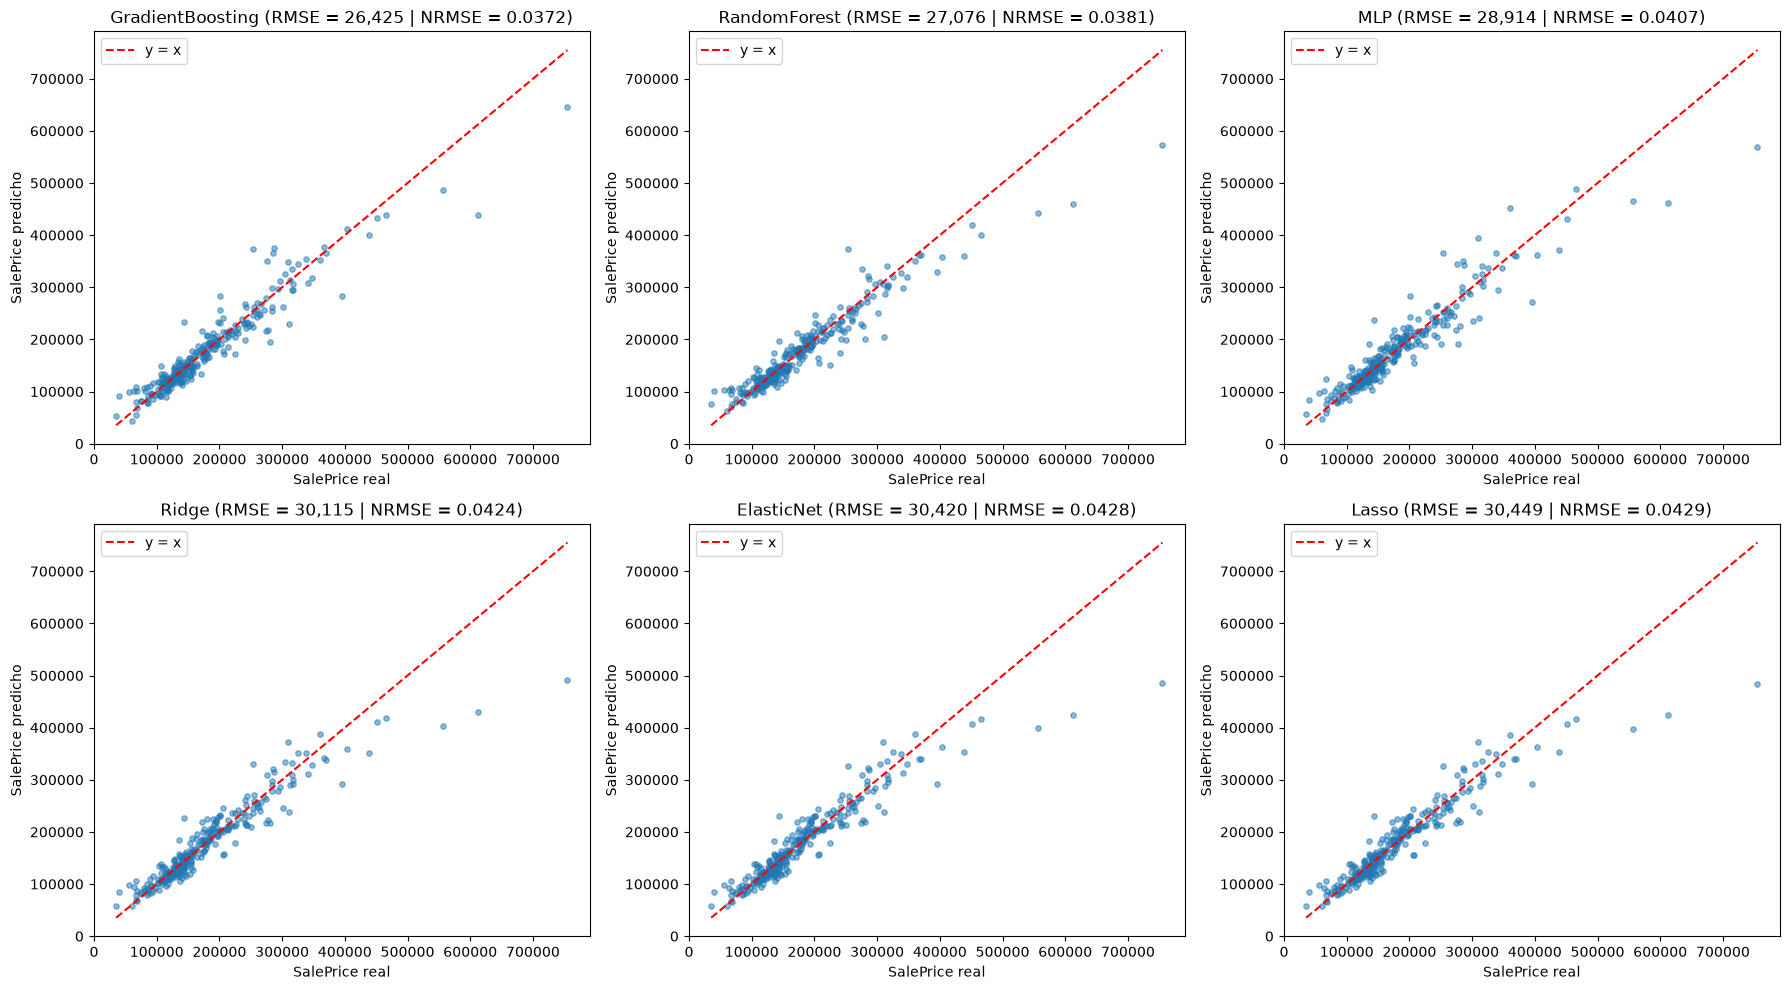

In [8]:
y_val_real = np.expm1(y_val)
limites = [y_val_real.min(), y_val_real.max()]

N_COLS = 3
n_rows = int(np.ceil(len(torneo) / N_COLS))
fig_real_vs_pred, axes = plt.subplots(n_rows, N_COLS, figsize=(6 * N_COLS, 5 * n_rows))
axes = axes.flatten()

for ax, fila in zip(axes, torneo.itertuples()):
    ax.scatter(y_val_real, np.expm1(predicciones_val[fila.modelo]), alpha=0.5, s=15)
    ax.plot(limites, limites, color="red", linestyle="--", label="y = x")
    ax.set_title(f"{fila.modelo} (RMSE = {fila.rmse_val:,.0f} | NRMSE = {fila.nrmse_val:.4f})")
    ax.set_xlabel(f"{TARGET} real")
    ax.set_ylabel(f"{TARGET} predicho")
    ax.legend()

# Ocultar los ejes sobrantes de la cuadrícula
for ax in axes[len(torneo):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### 8.2 Error en entrenamiento, validación cruzada y validación

RMSE real de cada modelo en los tres conjuntos. Un modelo bien generalizado tiene errores similares en los tres; un error de entrenamiento mucho menor que el de validación cruzada y validación indica sobreajuste.

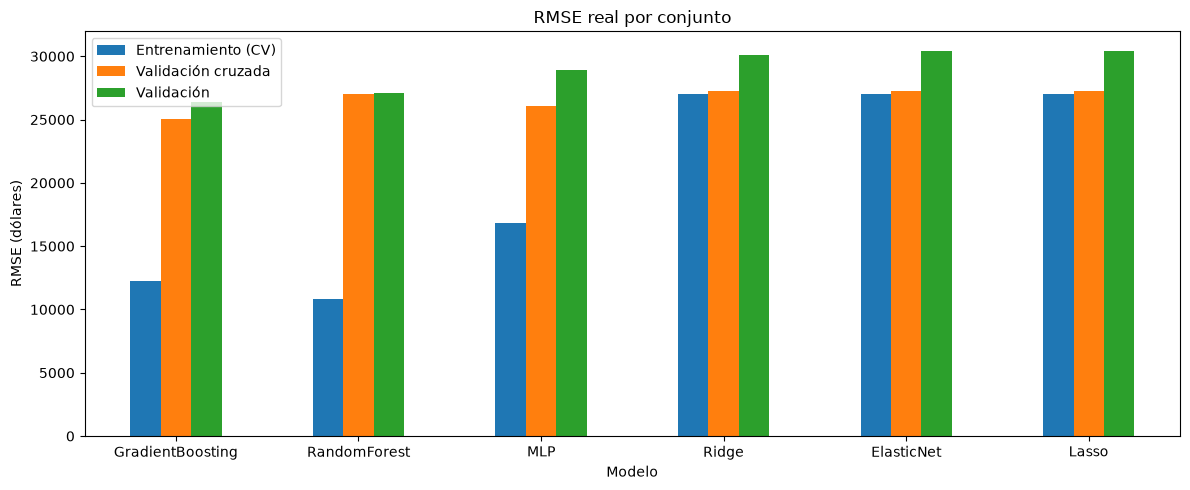

In [9]:
ax = torneo.set_index("modelo")[["rmse_train", "rmse_cv", "rmse_val"]].plot.bar(figsize=(12, 5), rot=0)
ax.set_title("RMSE real por conjunto")
ax.set_xlabel("Modelo")
ax.set_ylabel("RMSE (dólares)")
ax.legend(["Entrenamiento (CV)", "Validación cruzada", "Validación"])
fig_rmse = ax.get_figure()
plt.tight_layout()
plt.show()

## 9. Almacenamiento del modelo ganador

Selección automática del modelo con menor RMSE en validación (primera fila del torneo) y almacenamiento de su pipeline completo en `models/best_model_pipeline.pkl`. El pipeline incluye la ingeniería de características y el modelo con los hiperparámetros ganadores, entrenados con el conjunto de entrenamiento (80%), por lo que su desempeño corresponde exactamente al reportado en el torneo. Recibe datos crudos y predice `SalePrice` en escala log1p.

In [10]:
BEST_MODEL_PATH = MODELS_DIR / "best_model_pipeline.pkl"

modelo_ganador = torneo.iloc[0]["modelo"]
best_model_pipeline = busquedas[modelo_ganador].best_estimator_

joblib.dump(best_model_pipeline, BEST_MODEL_PATH)

print(f"Modelo ganador: {modelo_ganador}")
print(f"Hiperparámetros: {busquedas[modelo_ganador].best_params_}")
print(f"RMSE val: {torneo.iloc[0]['rmse_val']:,.0f} | NRMSE val: {torneo.iloc[0]['nrmse_val']:.4f}")
print(f"Guardado: {BEST_MODEL_PATH}")

Modelo ganador: GradientBoosting
Hiperparámetros: {'model__learning_rate': 0.06, 'model__max_depth': 3, 'model__n_estimators': 300}
RMSE val: 26,425 | NRMSE val: 0.0372
Guardado: C:\Users\MO\Desktop\Business Intelligence\8vo. trimestre\Product_Development\Clase\House_pricing\models\best_model_pipeline.pkl


## 10. Registro de experimentos en MLflow

Configuración del seguimiento de experimentos. El tracking es local: los runs y el Model Registry se guardan en `mlflow.db` (SQLite) y los artefactos en `mlruns/`, ambos en la raíz del proyecto y fuera de git. Para explorarlos en la interfaz web, desde la raíz del proyecto:

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

In [11]:
experimento = configurar_mlflow(MLFLOW_EXPERIMENT_TRAINING)

print(f"Tracking URI: {mlflow.get_tracking_uri()}")
print(f"Experimento: {experimento.name} (id {experimento.experiment_id})")

2026/11/10 19:23:08 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/10 19:23:09 INFO mlflow.store.db.utils: Updating database tables


Tracking URI: sqlite:///C:/Users/MO/Desktop/Business Intelligence/8vo. trimestre/Product_Development/Clase/House_pricing/mlflow.db
Experimento: house_pricing_entrenamiento (id 1)


### 10.1 Runs del torneo

Cada ejecución del torneo se registra como un run padre (`torneo_modelos`) con un run anidado por modelo:

- **Run padre**: dataset de entrenamiento, configuración del pipeline, parámetros de la partición y la validación cruzada, tabla del torneo y gráficas comparativas de la sección 8.
- **Runs por modelo**: hiperparámetros ganadores, métricas del torneo (`rmse_train`, `rmse_cv`, `rmse_val`, `nrmse_val`, `brecha_train_val`), RMSE de cada fold (`rmse_fold`, con el número de fold como step), resultados de todas las configuraciones evaluadas por `GridSearchCV`, gráfica real vs predicho y el pipeline entrenado como modelo de MLflow.

La firma del modelo declara las columnas enteras como `float`, ya que los datos nuevos pueden traer faltantes en ellas (por ejemplo `GarageCars` en `test.csv`).

In [12]:
columnas_enteras = X_train.select_dtypes("integer").columns
X_firma = X_train.astype({col: "float64" for col in columnas_enteras})

dataset_train = mlflow.data.from_pandas(
    train_raw, source=str(DATA_PATH / TRAIN_FILE), targets=TARGET, name=TRAIN_FILE
)

modelos_mlflow = {}

with mlflow.start_run(run_name="torneo_modelos") as run_torneo:
    mlflow.log_input(dataset_train, context="training")
    mlflow.log_params({
        "target": TARGET,
        "transformacion_target": "log1p",
        "n_features": len(INPUT_FEATURES),
        "test_size": TEST_SIZE,
        "random_state": RANDOM_STATE,
        "n_folds": N_FOLDS,
        "n_train": len(X_train),
        "n_val": len(X_val),
        "modelos": ", ".join(modelos),
    })
    mlflow.log_artifact(str(CONFIG_PATH), artifact_path="config")
    mlflow.log_table(torneo, artifact_file="torneo.json")
    mlflow.log_figure(fig_real_vs_pred, "graficas/real_vs_predicho.png")
    mlflow.log_figure(fig_rmse, "graficas/rmse_por_conjunto.png")
    mlflow.set_tag("modelo_ganador", modelo_ganador)

    for fila in torneo.itertuples():
        busqueda = busquedas[fila.modelo]
        resultados = busqueda.cv_results_
        best = busqueda.best_index_

        with mlflow.start_run(run_name=fila.modelo, nested=True) as run_modelo:
            mlflow.set_tags({"modelo": fila.modelo, "posicion_torneo": fila.Index + 1})
            mlflow.log_params({param.split("__")[-1]: valor for param, valor in busqueda.best_params_.items()})
            mlflow.log_metrics({
                "rmse_train": fila.rmse_train,
                "rmse_cv": fila.rmse_cv,
                "rmse_cv_std": resultados["std_test_score"][best],
                "rmse_val": fila.rmse_val,
                "nrmse_val": fila.nrmse_val,
                "brecha_train_val": fila.brecha_train_val,
            })

            # RMSE de la mejor configuración en cada fold de la validación cruzada
            for fold in range(N_FOLDS):
                mlflow.log_metric("rmse_fold", -resultados[f"split{fold}_test_score"][best], step=fold)

            # Todas las configuraciones evaluadas en la búsqueda en rejilla
            configuraciones = pd.DataFrame({
                "params": [str({p.split("__")[-1]: v for p, v in params.items()}) for params in resultados["params"]],
                "rmse_cv": -resultados["mean_test_score"],
                "rmse_cv_std": resultados["std_test_score"],
                "rmse_train": -resultados["mean_train_score"],
                "rank": resultados["rank_test_score"],
            }).sort_values("rank")
            mlflow.log_table(configuraciones, artifact_file="busqueda/configuraciones.json")

            fig, ax = plt.subplots(figsize=(6, 5))
            ax.scatter(y_val_real, np.expm1(predicciones_val[fila.modelo]), alpha=0.5, s=15)
            ax.plot(limites, limites, color="red", linestyle="--", label="y = x")
            ax.set_title(f"{fila.modelo} (RMSE val = {fila.rmse_val:,.0f})")
            ax.set_xlabel(f"{TARGET} real")
            ax.set_ylabel(f"{TARGET} predicho")
            ax.legend()
            mlflow.log_figure(fig, "graficas/real_vs_predicho.png")
            plt.close(fig)

            info_modelo = mlflow.sklearn.log_model(
                busqueda.best_estimator_,
                name="model",
                signature=infer_signature(X_firma, busqueda.predict(X_firma)),
                input_example=X_firma.head(5),
        skops_trusted_types=SKOPS_TRUSTED_TYPES,
            )
            modelos_mlflow[fila.modelo] = {"run_id": run_modelo.info.run_id, "model_uri": info_modelo.model_uri}

        print(f"{fila.Index + 1}. {fila.modelo}: run {run_modelo.info.run_id}")

print(f"Run del torneo: {run_torneo.info.run_id}")

1. GradientBoosting: run bc9ead20e3514791b8447532d23606e3


2. RandomForest: run 74db5afc35ac4e6fa9a0c5059b595a70


3. MLP: run 40d1d08bf5ae48ef8ba7c4d673596c76


4. Ridge: run fa94adb666cb43af900b5b9a82be889c


5. ElasticNet: run 530be527f046428aa2b14bd7ade0f0f3


6. Lasso: run 4594198c15204b92a6986300aed81a17
Run del torneo: b6d24bf5cd634812a9074507ecea9e0c


### 10.2 Registro de champion y challengers

Los tres mejores modelos del torneo (menor RMSE en validación) se registran como nuevas versiones del modelo `house_pricing_model` en el Model Registry y se identifican con aliases:

| Posición | Alias |
|---|---|
| 1 | `champion` |
| 2 | `challenger_1` |
| 3 | `challenger_2` |

Un alias apunta a una única versión, por lo que al volver a ejecutar el notebook los aliases se mueven a las nuevas versiones y las anteriores quedan en el historial. El notebook de inferencia carga el modelo con `models:/house_pricing_model@champion`, sin depender del número de versión.

In [13]:
cliente = MlflowClient()
ALIASES = [CHAMPION_ALIAS] + CHALLENGER_ALIASES

registro = []
for alias, fila in zip(ALIASES, torneo.itertuples()):
    datos = modelos_mlflow[fila.modelo]
    version = mlflow.register_model(
        datos["model_uri"],
        REGISTERED_MODEL_NAME,
        tags={"modelo": fila.modelo, "posicion_torneo": str(fila.Index + 1), "rmse_val": f"{fila.rmse_val:.0f}"},
    )
    cliente.set_registered_model_alias(REGISTERED_MODEL_NAME, alias, version.version)
    cliente.update_model_version(
        REGISTERED_MODEL_NAME,
        version.version,
        description=(
            f"{fila.modelo}, posición {fila.Index + 1} del torneo (RMSE val = {fila.rmse_val:,.0f}). "
            "Pipeline de ingeniería de características + modelo: recibe las features crudas y predice log1p(SalePrice)."
        ),
    )
    cliente.set_tag(datos["run_id"], "alias_registro", alias)
    registro.append({
        "alias": alias,
        "modelo": fila.modelo,
        "version": version.version,
        "rmse_val": fila.rmse_val,
        "run_id": datos["run_id"],
    })

cliente.update_registered_model(
    REGISTERED_MODEL_NAME,
    description=(
        "Modelos de House Pricing que predicen log1p(SalePrice) a partir de las features crudas. "
        "Alias champion: mejor RMSE en validación del último torneo; challenger_1 y challenger_2: segundo y tercer lugar."
    ),
)

pd.DataFrame(registro).style.format({"rmse_val": "{:,.0f}"})

Successfully registered model 'house_pricing_model'.
Created version '1' of model 'house_pricing_model'.
Registered model 'house_pricing_model' already exists. Creating a new version of this model...
Created version '2' of model 'house_pricing_model'.
Registered model 'house_pricing_model' already exists. Creating a new version of this model...
Created version '3' of model 'house_pricing_model'.


,alias,modelo,version,rmse_val,run_id
0,champion,GradientBoosting,1,"26,425",bc9ead20e3514791b8447532d23606e3
1,challenger_1,RandomForest,2,"27,076",74db5afc35ac4e6fa9a0c5059b595a70
2,challenger_2,MLP,3,"28,914",40d1d08bf5ae48ef8ba7c4d673596c76
